<a id='1'></a><center> <h3 style="background-color:orange; color:white" ><br>Date Master & Time Intelligence Dimension Analytics<br></h3></center>

# Introduction
This notebook provides complete exploratory analysis, dimensional feature engineering, and time-intelligence modeling on the **Date Master Calendar Dimension Table** (`Date_Master.csv`).

In relational data warehousing and business intelligence (BI) systems, a dedicated **Date Dimension Table** is foundational to the star-schema architecture. It provides a standardized temporal backbone that eliminates complex date calculations at query time and powers robust slice-and-dice analytics across years, quarters, months, weeks, and days.

### Key Objectives:
1. **Schema & Calendar Audit**: Validate temporal coverage across 2,557 consecutive days spanning 7 full calendar years (2018–2024), including leap-year verification (2020 and 2024).
2. **Dimension Feature Engineering**: Derive critical BI attributes including calendar quarters, weekend/weekday indicators, fiscal periods, and seasons.
3. **Working Day & Seasonality Diagnostics**: Analyze annual business-day distributions and monthly trading day variations.
4. **Time Intelligence Modeling**: Demonstrate how date dimensions facilitate Year-over-Year (YoY) and Quarter-over-Quarter (QoQ) comparative analysis.
5. **Visual Analytics Dashboard**: Deliver an executive 4-panel calendar visualization suite.


In [1]:
# 1. Imports & Visualization Configuration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (11, 4.5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

print("Libraries imported successfully!")


Libraries imported successfully!


---
## 1. Dataset Loading & Temporal Boundary Audit


In [2]:
# Load Date Master dataset
date_df = pd.read_csv('Date_Master.csv', parse_dates=['Master Date'])
print(f"Calendar Records: {date_df.shape[0]:,} days × {date_df.shape[1]} columns")
print(f"Date Coverage:    {date_df['Master Date'].min().strftime('%Y-%m-%d')} to {date_df['Master Date'].max().strftime('%Y-%m-%d')}")
print(f"Total Span:       {date_df['Master Date'].nunique():,} unique dates")

print("\nFirst 5 Records:")
date_df.head()


Calendar Records: 2,557 days × 8 columns
Date Coverage:    2018-01-01 to 2024-12-31
Total Span:       2,557 unique dates

First 5 Records:


,Master Date,Day,Month,Year,WeekDay,WeekDay Name,Month Name,Week Num
0,2018-01-01,1,1,2018,2,Monday,January,1
1,2018-01-02,2,1,2018,3,Tuesday,January,1
2,2018-01-03,3,1,2018,4,Wednesday,January,1
3,2018-01-04,4,1,2018,5,Thursday,January,1
4,2018-01-05,5,1,2018,6,Friday,January,1


In [3]:
# Data types & Null Value Audit
print("=== Schema Information ===")
date_df.info()
print(f"\nMissing values: {date_df.isnull().sum().sum()}")
print(f"Duplicate dates: {date_df['Master Date'].duplicated().sum()}")


=== Schema Information ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2557 entries, 0 to 2556
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Master Date   2557 non-null   datetime64[ns]
 1   Day           2557 non-null   int64         
 2   Month         2557 non-null   int64         
 3   Year          2557 non-null   int64         
 4   WeekDay       2557 non-null   int64         
 5   WeekDay Name  2557 non-null   object        
 6   Month Name    2557 non-null   object        
 7   Week Num      2557 non-null   int64         
dtypes: datetime64[ns](1), int64(5), object(2)
memory usage: 159.9+ KB

Missing values: 0
Duplicate dates: 0


In [4]:
# Annual Day Count & Leap Year Verification
annual_counts = date_df.groupby('Year').agg(
    Days_Count=('Master Date', 'count'),
    Start_Date=('Master Date', 'min'),
    End_Date=('Master Date', 'max')
)
annual_counts['Is_Leap_Year'] = annual_counts['Days_Count'] == 366

print("Annual Calendar Days & Leap Year Audit:")
annual_counts


Annual Calendar Days & Leap Year Audit:


,Days_Count,Start_Date,End_Date,Is_Leap_Year
Year,,,,
2018,365,2018-01-01,2018-12-31,False
2019,365,2019-01-01,2019-12-31,False
2020,366,2020-01-01,2020-12-31,True
2021,365,2021-01-01,2021-12-31,False
2022,365,2022-01-01,2022-12-31,False
2023,365,2023-01-01,2023-12-31,False
2024,366,2024-01-01,2024-12-31,True


---
## 2. Dimensional Feature Engineering

Enrich the calendar table with operational BI attributes:
- **Calendar Quarter** (`Q1`, `Q2`, `Q3`, `Q4`)
- **Year-Quarter** (`YYYY-Q#`)
- **Is_Weekend** (Binary indicator: 1 for Saturday/Sunday, 0 for Monday–Friday)
- **Day of Year** (`1` to `365/366`)
- **Season** (Winter, Spring, Summer, Fall)
- **Fiscal Quarter** (April–March convention)


In [5]:
# Feature Engineering
# 1. Calendar Quarter
date_df['Quarter'] = 'Q' + date_df['Master Date'].dt.quarter.astype(str)
date_df['Year_Quarter'] = date_df['Year'].astype(str) + '-' + date_df['Quarter']

# 2. Weekend vs Business Day Indicator
date_df['Is_Weekend'] = date_df['WeekDay Name'].isin(['Saturday', 'Sunday']).astype(int)
date_df['Day_Type'] = np.where(date_df['Is_Weekend'] == 1, 'Weekend', 'Business Day')

# 3. Day of Year
date_df['Day_Of_Year'] = date_df['Master Date'].dt.dayofyear

# 4. Astronomical Season
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Spring'
    elif month in [6, 7, 8]:
        return 'Summer'
    else:
        return 'Fall'

date_df['Season'] = date_df['Month'].apply(get_season)

# 5. Fiscal Quarter (April-March convention)
def get_fiscal_quarter(month):
    if month in [4, 5, 6]:
        return 'FQ1'
    elif month in [7, 8, 9]:
        return 'FQ2'
    elif month in [10, 11, 12]:
        return 'FQ3'
    else:
        return 'FQ4'

date_df['Fiscal_Quarter'] = date_df['Month'].apply(get_fiscal_quarter)

print("Engineered Calendar Features (Sample):")
date_df[['Master Date', 'Year_Quarter', 'Day_Type', 'Day_Of_Year', 'Season', 'Fiscal_Quarter']].head(6)


Engineered Calendar Features (Sample):


,Master Date,Year_Quarter,Day_Type,Day_Of_Year,Season,Fiscal_Quarter
0,2018-01-01,2018-Q1,Business Day,1,Winter,FQ4
1,2018-01-02,2018-Q1,Business Day,2,Winter,FQ4
2,2018-01-03,2018-Q1,Business Day,3,Winter,FQ4
3,2018-01-04,2018-Q1,Business Day,4,Winter,FQ4
4,2018-01-05,2018-Q1,Business Day,5,Winter,FQ4
5,2018-01-06,2018-Q1,Weekend,6,Winter,FQ4


---
## 3. Working Days & Operational Scheduling Analysis


In [6]:
# Business Days vs Weekend Days per Year
workday_summary = date_df.groupby(['Year', 'Day_Type']).size().unstack()
workday_summary['Total_Days'] = workday_summary.sum(axis=1)
workday_summary['Business_Day_Pct'] = (workday_summary['Business Day'] / workday_summary['Total_Days'] * 100).round(2)

print("Annual Business Days vs Weekend Days Breakdown:")
workday_summary


Annual Business Days vs Weekend Days Breakdown:


Day_Type,Business Day,Weekend,Total_Days,Business_Day_Pct
Year,,,,
2018,261,104,365,71.51
2019,261,104,365,71.51
2020,262,104,366,71.58
2021,261,104,365,71.51
2022,260,105,365,71.23
2023,260,105,365,71.23
2024,262,104,366,71.58


In [7]:
# Monthly Working Day Distribution
monthly_workdays = date_df.pivot_table(
    index='Month Name',
    columns='Year',
    values='Is_Weekend',
    aggfunc=lambda x: (x == 0).sum()
)

# Reorder chronologically
month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']
monthly_workdays = monthly_workdays.reindex(month_order)

print("Working Days (Mon-Fri) per Month by Year:")
monthly_workdays


Working Days (Mon-Fri) per Month by Year:


Year,2018,2019,2020,2021,2022,2023,2024
Month Name,,,,,,,
January,23,23,23,21,21,22,23
February,20,20,20,20,20,20,21
March,22,21,22,23,23,23,21
April,21,22,22,22,21,20,22
May,23,23,21,21,22,23,23
June,21,20,22,22,22,22,20
July,22,23,23,22,21,21,23
August,23,22,21,22,23,23,22
September,20,21,22,22,22,21,21


In [8]:
# Day of Week Distribution across 7 Years
dow_summary = date_df.groupby('WeekDay Name').agg(
    Total_Occurrences=('Master Date', 'count'),
    Pct_of_Total=('Master Date', lambda x: (len(x) / len(date_df)) * 100)
).round(2)

dow_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dow_summary = dow_summary.reindex(dow_order)

print("Day of Week Occurrences across 7 Years (2018–2024):")
dow_summary


Day of Week Occurrences across 7 Years (2018–2024):


,Total_Occurrences,Pct_of_Total
WeekDay Name,,
Monday,366,14.31
Tuesday,366,14.31
Wednesday,365,14.27
Thursday,365,14.27
Friday,365,14.27
Saturday,365,14.27
Sunday,365,14.27


---
## 4. Time Intelligence & Temporal Aggregation Modeling

Demonstrate time-series rollups across Quarters and Seasons.


In [9]:
# Days per Quarter by Year
quarter_pivot = date_df.pivot_table(
    index='Quarter',
    columns='Year',
    values='Master Date',
    aggfunc='count'
)
print("Calendar Days per Quarter (Showing Q1 Leap Year differences in 2020 & 2024):")
quarter_pivot


Calendar Days per Quarter (Showing Q1 Leap Year differences in 2020 & 2024):


Year,2018,2019,2020,2021,2022,2023,2024
Quarter,,,,,,,
Q1,90,90,91,90,90,90,91
Q2,91,91,91,91,91,91,91
Q3,92,92,92,92,92,92,92
Q4,92,92,92,92,92,92,92


In [10]:
# Seasonal Distribution Breakdown
season_summary = date_df.groupby(['Season', 'Day_Type']).size().unstack()
season_summary['Total_Days'] = season_summary.sum(axis=1)
season_summary['Workday_Share%'] = (season_summary['Business Day'] / season_summary['Total_Days'] * 100).round(2)

print("Seasonal Days & Workday Proportion:")
season_summary


Seasonal Days & Workday Proportion:


Day_Type,Business Day,Weekend,Total_Days,Workday_Share%
Season,,,,
Fall,455,182,637,71.43
Spring,461,183,644,71.58
Summer,460,184,644,71.43
Winter,451,181,632,71.36


---
## 5. Visual Time-Intelligence Dashboard


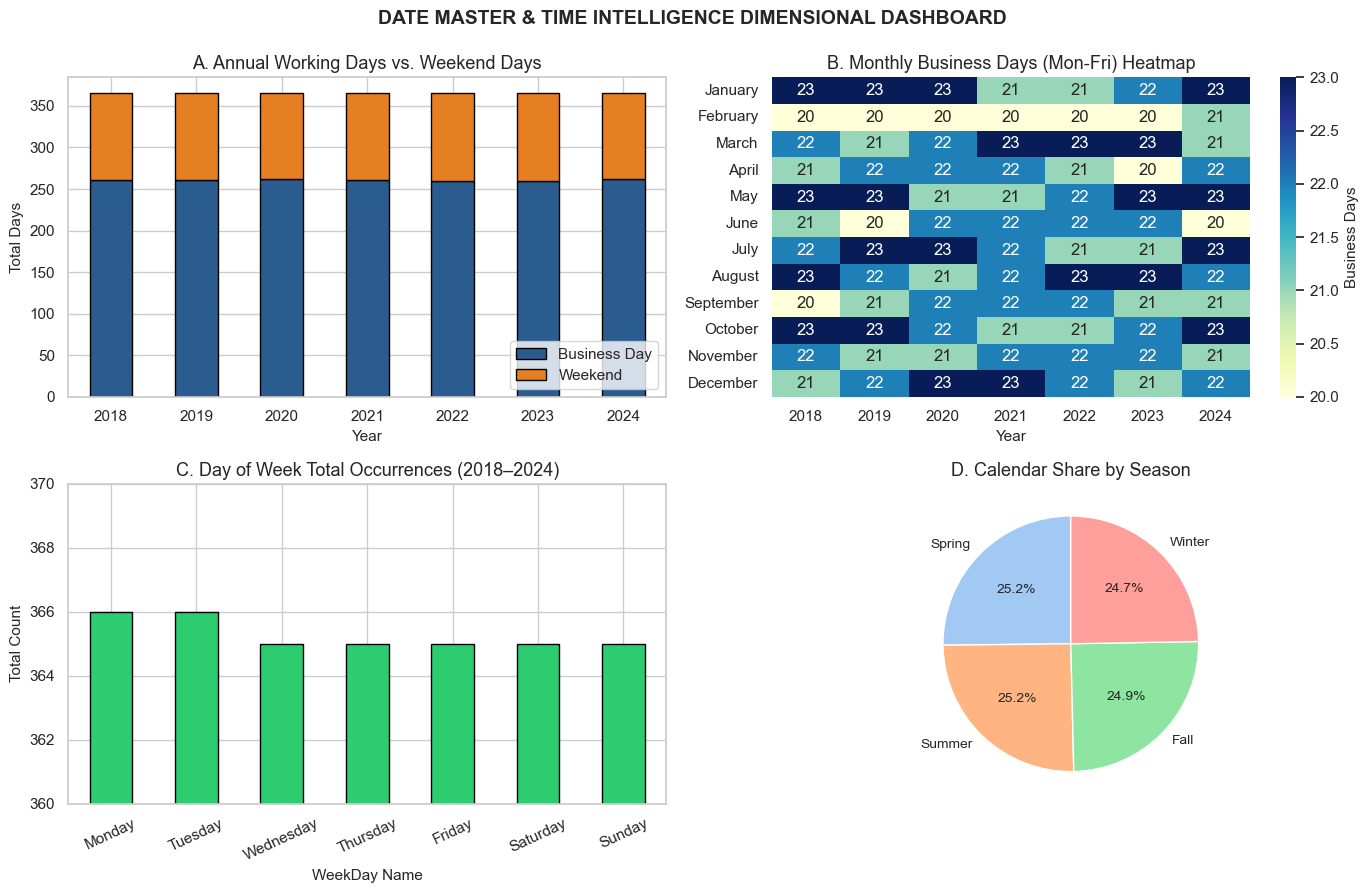

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Panel 1: Annual Working Days vs Weekend Days
workday_summary[['Business Day', 'Weekend']].plot(kind='bar', stacked=True, ax=axes[0, 0],
                                                 color=['#2b5c8f', '#e67e22'], edgecolor='black')
axes[0, 0].set_title('A. Annual Working Days vs. Weekend Days')
axes[0, 0].set_ylabel('Total Days')
axes[0, 0].tick_params(axis='x', rotation=0)
axes[0, 0].legend(loc='lower right')

# Panel 2: Monthly Working Days Heatmap
sns.heatmap(monthly_workdays, annot=True, fmt='d', cmap='YlGnBu', ax=axes[0, 1], cbar_kws={'label': 'Business Days'})
axes[0, 1].set_title('B. Monthly Business Days (Mon-Fri) Heatmap')
axes[0, 1].set_ylabel('')

# Panel 3: Day of Week Total Counts
dow_summary['Total_Occurrences'].plot(kind='bar', ax=axes[1, 0], color='#2ecc71', edgecolor='black')
axes[1, 0].set_title('C. Day of Week Total Occurrences (2018–2024)')
axes[1, 0].set_ylabel('Total Count')
axes[1, 0].set_ylim(360, 370)
axes[1, 0].tick_params(axis='x', rotation=25)

# Panel 4: Seasonal Breakdown Pie Chart
date_df['Season'].value_counts().plot(kind='pie', ax=axes[1, 1], autopct='%1.1f%%',
                                     colors=sns.color_palette('pastel', 4), startangle=90, textprops={'fontsize': 10})
axes[1, 1].set_title('D. Calendar Share by Season')
axes[1, 1].set_ylabel('')

plt.suptitle('DATE MASTER & TIME INTELLIGENCE DIMENSIONAL DASHBOARD', fontsize=14, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()


---
## 6. Executive Summary & Star-Schema Best Practices


In [12]:
total_days = len(date_df)
total_workdays = (date_df['Is_Weekend'] == 0).sum()
total_weekends = (date_df['Is_Weekend'] == 1).sum()

print("=" * 60)
print("         DATE MASTER CALENDAR DIMENSION SUMMARY")
print("=" * 60)
print(f"  Total Days In Calendar:        {total_days:>8,} days")
print(f"  Calendar Range:                2018-01-01 to 2024-12-31")
print(f"  Total Calendar Years:          7 full years")
print(f"  Total Business Days (Mon-Fri): {total_workdays:>8,} ({total_workdays/total_days*100:.2f}%)")
print(f"  Total Weekend Days (Sat-Sun):  {total_weekends:>8,} ({total_weekends/total_days*100:.2f}%)")
print(f"  Leap Years Included:           2020 (366 days), 2024 (366 days)")
print("=" * 60)
print("\nCore Dimensional Modeling Best Practices:")
print("  1. Continuous Date Range: No missing dates to ensure accurate time-intelligence calculations (YTD, MTD, YoY).")
print("  2. Standardized Granularity: Day-level primary key (Master Date) links seamlessly to transactional fact tables.")
print("  3. Precomputed Attributes: Quarters, fiscal periods, and weekend flags avoid costly run-time transformations.")
print("  4. Role-Playing Flexibility: Can serve as Order Date, Ship Date, or Due Date in relational BI models.")


         DATE MASTER CALENDAR DIMENSION SUMMARY
  Total Days In Calendar:           2,557 days
  Calendar Range:                2018-01-01 to 2024-12-31
  Total Calendar Years:          7 full years
  Total Business Days (Mon-Fri):    1,827 (71.45%)
  Total Weekend Days (Sat-Sun):       730 (28.55%)
  Leap Years Included:           2020 (366 days), 2024 (366 days)

Core Dimensional Modeling Best Practices:
  1. Continuous Date Range: No missing dates to ensure accurate time-intelligence calculations (YTD, MTD, YoY).
  2. Standardized Granularity: Day-level primary key (Master Date) links seamlessly to transactional fact tables.
  3. Precomputed Attributes: Quarters, fiscal periods, and weekend flags avoid costly run-time transformations.
  4. Role-Playing Flexibility: Can serve as Order Date, Ship Date, or Due Date in relational BI models.
